# EXP-012: Cân bằng lớp cho KNN

- Ngày: 22/11/2026 (lập notebook).
- Mã thực nghiệm: exp012.
- So với lần trước: exp007. Giữ tham số theo từng người test, thêm RandomOverSampler trên train.
- Ngày chạy được lưu khi thực hiện huấn luyện.

**Notebook trình bày:** [Mai_EXP-012_KNN_balancing.ipynb](../../../notebooks/experiments/Mai_EXP-012_KNN_balancing.ipynb).


## 1. Mục tiêu và giả thuyết

**Mục tiêu:** Kiểm tra cân bằng số mẫu trên train có giúp KNN dự đoán các lớp tốt hơn so với KNN tuning chưa cân bằng không.

**Giả thuyết:** Nhân bản mẫu của lớp ít dữ liệu có thể làm thay đổi các láng giềng được KNN xét. Macro-F1 và Balanced Accuracy có thể tăng, nhưng cũng có thể giảm nếu các điểm nhân bản làm mất cân đối vùng lân cận. Chưa đặt trước mức tăng khi chưa chạy.


## 2. Cấu hình

Giữ cấu hình trong `experiment.ipynb` và `config.yaml` của EXP-012.

| Thành phần | Chưa cân bằng (`plain`) | Cân bằng (`balanced`) |
| --- | --- | --- |
| Tham số KNN | Lấy đúng `n_neighbors`, `metric`, `weights` theo task và người test từ EXP-007 | Giữ như `plain` |
| Giá trị thiếu | Trung vị học từ train | Giữ như `plain` |
| Chuẩn hóa | StandardScaler học từ train | Giữ như `plain` |
| Cân bằng lớp | Không | RandomOverSampler, `sampling_strategy="auto"`, seed 42 |
| Đặc trưng | Đủ 68 biến | Đủ 68 biến |

KNN không dùng `class_weight`. RandomOverSampler nhân bản mẫu trong train để các lớp có cùng số mẫu. Không tạo thêm dữ liệu test. Không chọn lại tham số KNN và không dùng điểm test để chọn cách cân bằng.


In [5]:
from pathlib import Path
import json
import subprocess
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd()
repo = next(p for p in (here, *here.parents) if (p / 'scripts/run_exp012_knn.py').is_file())
package = repo / 'experiments/03_balancing/EXP-012_KNN'
config_path = package / 'config.yaml'
config = yaml.safe_load(config_path.read_text(encoding='utf-8'))
reference = repo / config['reference_dir']
fixed_params = pd.read_csv(reference / 'best_params_by_subject.csv')
assert len(fixed_params) == 30 and not fixed_params.duplicated(['task', 'subject_id']).any()
display(fixed_params)


,task,subject_id,n_neighbors,metric,weights
0,binary,S10,5,manhattan,distance
1,binary,S11,5,manhattan,distance
2,binary,S13,5,manhattan,distance
3,binary,S14,5,manhattan,distance
4,binary,S15,5,manhattan,distance
5,binary,S16,5,manhattan,distance
6,binary,S17,5,manhattan,distance
7,binary,S2,5,manhattan,distance
8,binary,S3,5,manhattan,distance
9,binary,S4,5,manhattan,distance


## 3. Cách thực hiện

Dùng physiological68 gồm 6.189 cửa sổ, 68 đặc trưng và 15 người. Nhị phân: 0 là không stress, 1 là stress. Ba lớp: 1 là baseline, 2 là stress, 3 là amusement.

Mỗi fold giữ riêng 1 người test và dùng 14 người train. Lấy tham số EXP-007 theo đúng task và người test. Fit imputer và scaler trên train. Với phiên bản cân bằng, nhân bản mẫu sau hai bước này. Sau đó fit KNN và dự đoán người test.

Chạy 15 fold cho mỗi bài toán. Có 30 outer fold và hai phiên bản, tổng 60 dòng kết quả. Điểm train tính trên dữ liệu train gốc trước khi nhân bản. Kết quả hai phiên bản dùng cùng cách chia người và cùng môi trường.

Fit lại KNN chưa cân bằng để lấy cặp so sánh cùng môi trường. So sánh dự đoán của phiên bản này với EXP-007 và ghi lại số dự đoán khác nhau. EXP-007 đã chọn tham số bằng inner CV. EXP-012 chỉ giữ tham số đó để kiểm tra riêng cân bằng lớp.


In [ ]:
RUN_TRAIN = False

if RUN_TRAIN:
    subprocess.run([
        str(repo / '.venv-g1/Scripts/python.exe'), '-X', 'utf8',
        str(repo / 'scripts/run_exp012_knn.py'), '--config', str(config_path),
    ], cwd=repo, check=True)


## 4. Kết quả

Các chỉ số gồm Accuracy, Macro-F1 và Balanced Accuracy. Tính riêng cho từng người rồi lấy trung bình và SD qua 15 người. Thanh sai số là SD, không phải khoảng tin cậy.

Bảng và biểu đồ bên dưới so sánh chưa cân bằng với cân bằng. Phần train–test cho biết mô hình khớp dữ liệu đã học và dự đoán trên người mới khác nhau thế nào. Confusion matrix gộp cửa sổ giúp xem lỗi theo lớp, không thay thế điểm trung bình theo người.


accuracy         macro_f1         balanced_accuracy  \
                        mean     std     mean     std              mean   
task       variant                                                        
binary     balanced   0.8370  0.0921   0.7949  0.1178            0.8068   
           plain      0.8370  0.0900   0.7862  0.1270            0.7966   
multiclass balanced   0.6355  0.1187   0.5530  0.1155            0.5709   
           plain      0.6484  0.1146   0.5501  0.1149            0.5640   

                            train_accuracy      train_macro_f1       \
                        std           mean  std           mean  std   
task       variant                                                    
binary     balanced  0.1163            1.0  0.0            1.0  0.0   
           plain     0.1260            1.0  0.0            1.0  0.0   
multiclass balanced  0.1124            1.0  0.0            1.0  0.0   
           plain     0.1073            1.0  0.0            1.0  0.0   

                    train_balanced_accuracy       
                                       mean  std  
task       variant                                
binary     balanced                     1.0  0.0  
           plain                        1.0  0.0  
multiclass balanced                     1.0  0.0  
           plain                        1.0  0.0

before   after
task       label                
binary     0      4051.6  4051.6
           1      1724.8  4051.6
multiclass 1      3145.3  3145.3
           2      1724.8  3145.3
           3       906.3  3145.3

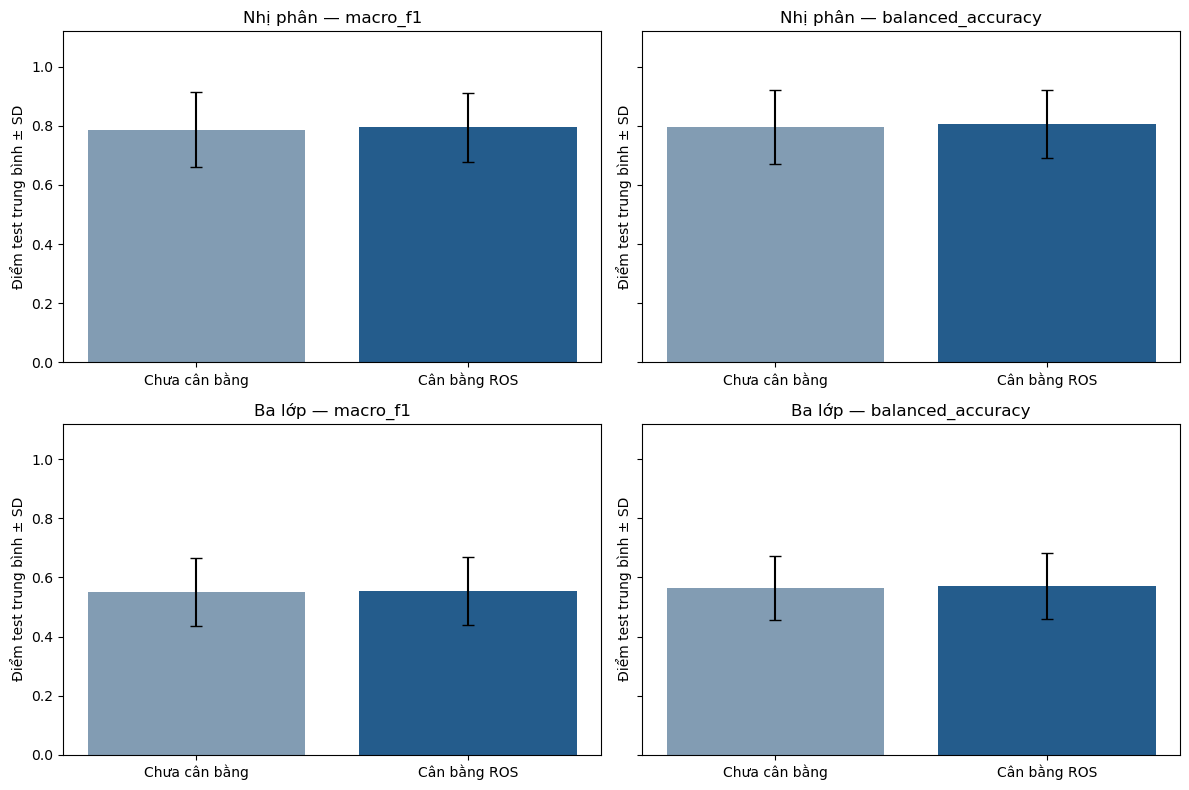

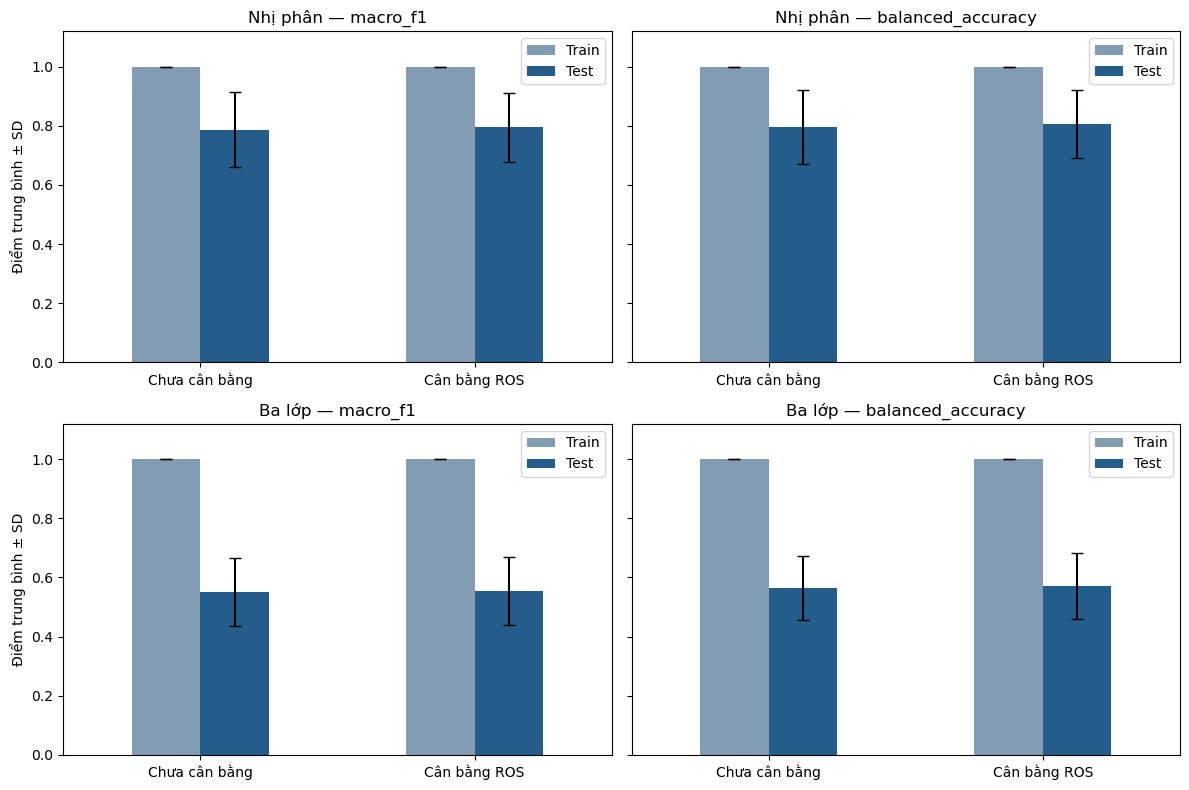

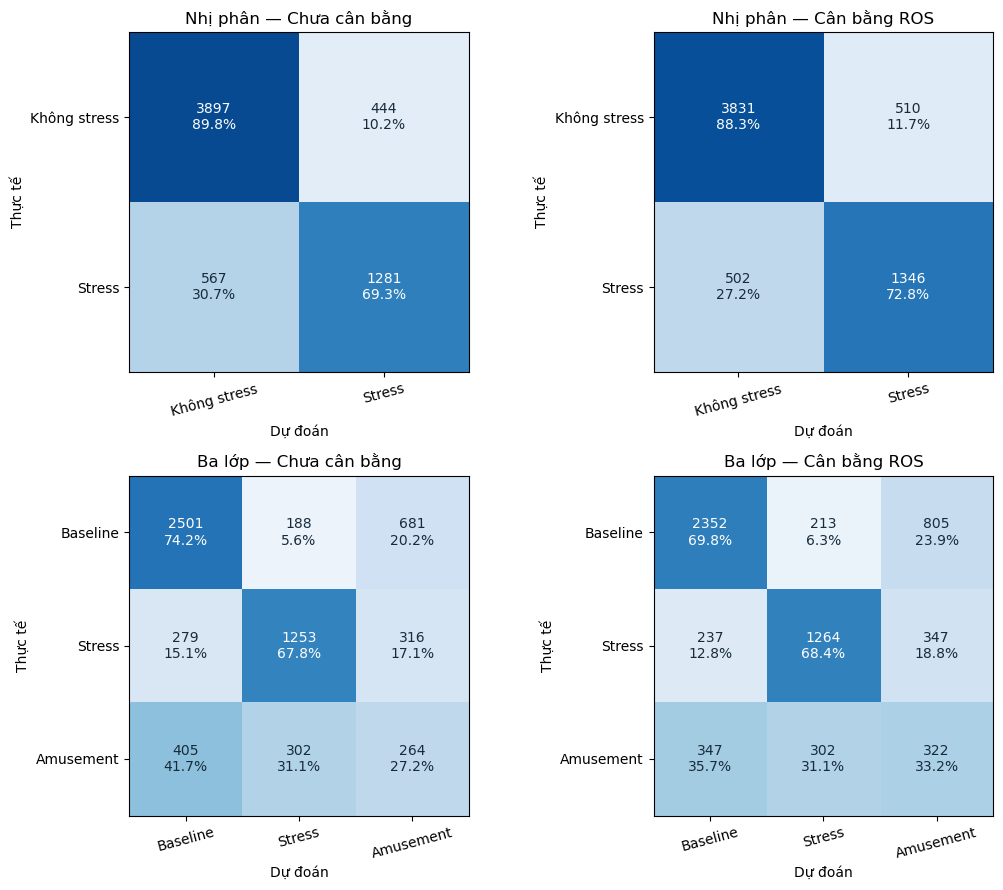

In [7]:
ready = (package / 'verification.json').exists()
if ready:
    proof = json.loads((package / 'verification.json').read_text(encoding='utf-8'))
    assert proof['status'] == 'passed' and proof['scope'] == 'main'
    assert proof['outer_folds'] == 30 and proof['paired_result_rows'] == 60
    scores = pd.read_csv(package / 'results.csv')
    predictions = pd.read_csv(package / 'predictions.csv')
    class_counts = pd.read_csv(package / 'class_counts.csv')
    assert len(scores) == 60 and not scores.duplicated(['task', 'subject_id', 'variant']).any()
    assert set(scores.variant) == {'plain', 'balanced'}
    assert all(len(g) == g.subject_id.nunique() == 15 for _, g in scores.groupby(['task', 'variant']))
    fields = ['accuracy', 'macro_f1', 'balanced_accuracy', 'train_accuracy', 'train_macro_f1', 'train_balanced_accuracy']
    display(scores.groupby(['task', 'variant'])[fields].agg(['mean', 'std']).round(4))
    display(class_counts.loc[class_counts.variant.eq('balanced')].groupby(['task', 'label'])[['before', 'after']].mean().round(1))

    figures = package / 'figures'
    figures.mkdir(exist_ok=True)
    task_names = {'binary': 'Nhị phân', 'multiclass': 'Ba lớp'}
    variant_names = {'plain': 'Chưa cân bằng', 'balanced': 'Cân bằng ROS'}
    order = ['plain', 'balanced']
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(['binary', 'multiclass']):
        part = scores.loc[scores.task.eq(task)]
        for col, metric in enumerate(['macro_f1', 'balanced_accuracy']):
            means = part.groupby('variant')[metric].mean().reindex(order)
            sd = part.groupby('variant')[metric].std(ddof=1).reindex(order)
            axes[row, col].bar([variant_names[v] for v in order], means, yerr=sd, capsize=4, color=['#829CB3', '#245C8C'])
            axes[row, col].set_title(f'{task_names[task]} — {metric}')
            axes[row, col].set_ylim(0, 1.12)
            axes[row, col].set_ylabel('Điểm test trung bình ± SD')
    fig.tight_layout()
    fig.savefig(figures / 'knn_plain_vs_balanced.png', dpi=150, bbox_inches='tight')
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(['binary', 'multiclass']):
        part = scores.loc[scores.task.eq(task)]
        for col, metric in enumerate(['macro_f1', 'balanced_accuracy']):
            columns = [f'train_{metric}', metric]
            means = part.groupby('variant')[columns].mean().reindex(order)
            sd = part.groupby('variant')[columns].std(ddof=1).reindex(order)
            rename = {columns[0]: 'Train', metric: 'Test'}
            means.rename(index=variant_names, columns=rename).plot.bar(
                yerr=sd.rename(index=variant_names, columns=rename), ax=axes[row, col],
                rot=0, capsize=4, color=['#829CB3', '#245C8C'])
            axes[row, col].set_title(f'{task_names[task]} — {metric}')
            axes[row, col].set_ylim(0, 1.12)
            axes[row, col].set_xlabel('')
            axes[row, col].set_ylabel('Điểm trung bình ± SD')
    fig.tight_layout()
    fig.savefig(figures / 'train_vs_test.png', dpi=150, bbox_inches='tight')
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for row, task in enumerate(['binary', 'multiclass']):
        labels = [0, 1] if task == 'binary' else [1, 2, 3]
        names = ['Không stress', 'Stress'] if task == 'binary' else ['Baseline', 'Stress', 'Amusement']
        for col, variant in enumerate(order):
            part = predictions.loc[predictions.task.eq(task) & predictions.variant.eq(variant)]
            matrix = pd.crosstab(part.y_true, part.y_pred).reindex(index=labels, columns=labels, fill_value=0)
            normalized = matrix.div(matrix.sum(axis=1), axis=0).fillna(0)
            ax = axes[row, col]
            ax.imshow(normalized.to_numpy(), cmap='Blues', vmin=0, vmax=1)
            for i in range(len(labels)):
                for j in range(len(labels)):
                    value = normalized.iloc[i, j]
                    ax.text(j, i, f'{matrix.iloc[i, j]}\n{value:.1%}', ha='center', va='center', color='white' if value > .55 else '#172B3A')
            ax.set_xticks(range(len(labels)), names, rotation=15)
            ax.set_yticks(range(len(labels)), names)
            ax.set_title(f'{task_names[task]} — {variant_names[variant]}')
            ax.set_xlabel('Dự đoán')
            ax.set_ylabel('Thực tế')
    fig.tight_layout()
    fig.savefig(figures / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Chưa có kết quả đầy đủ của EXP-012.')


## 5. So sánh với các lần trước

EXP-007 là mốc KNN tuning chưa cân bằng. Bảng đầu trình bày điểm EXP-007 đã lưu. Bảng sau so sánh hai phiên bản fit lại của EXP-012 trên cùng người test. Chênh lệch được tính bằng cân bằng trừ chưa cân bằng.

Nếu dự đoán `plain` khác EXP-007, không coi hai kết quả là khớp nhau. Số dự đoán khác được ghi riêng. Cặp `plain` và `balanced` vẫn dùng cùng môi trường và tham số để đánh giá riêng tác động của nhân bản mẫu.


In [8]:
reference_scores = pd.read_csv(reference / 'results.csv')
display(reference_scores.groupby('task')[['macro_f1', 'balanced_accuracy']].agg(['mean', 'std']).round(4))
if ready:
    comparison = pd.read_csv(package / 'comparison_exp007.csv')
    assert len(comparison) == 30 and not comparison.duplicated(['task', 'subject_id']).any()
    columns = ['accuracy_plain', 'accuracy_balanced', 'accuracy_delta',
               'macro_f1_plain', 'macro_f1_balanced', 'macro_f1_delta',
               'balanced_accuracy_plain', 'balanced_accuracy_balanced', 'balanced_accuracy_delta']
    display(comparison.groupby('task')[columns].mean().round(4))
    print('Số dự đoán của KNN chưa cân bằng khác EXP-007:', proof['plain_prediction_changes_vs_exp007'])


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.7862  0.1270            0.7966  0.1260
multiclass   0.5501  0.1149            0.5640  0.1073

,accuracy_plain,accuracy_balanced,accuracy_delta,macro_f1_plain,macro_f1_balanced,macro_f1_delta,balanced_accuracy_plain,balanced_accuracy_balanced,balanced_accuracy_delta
task,,,,,,,,,
binary,0.8370,0.8370,-0.0001,0.7862,0.7949,0.0087,0.7966,0.8068,0.0102
multiclass,0.6484,0.6355,-0.0129,0.5501,0.5530,0.0029,0.5640,0.5709,0.0070


Số dự đoán của KNN chưa cân bằng khác EXP-007: 0


## 6. Nhận xét

Xem giả thuyết có đúng với từng bài toán không. Kiểm tra điểm trung bình, số người tăng hoặc giảm F1 và lỗi theo lớp. Quan sát cả khoảng cách train–test. Chưa có kết quả đầy đủ thì chưa kết luận cân bằng lớp có hiệu quả.

KNN có thể nhạy với các điểm có cùng khoảng cách. Các mẫu nhân bản cũng có thể chiếm nhiều vị trí trong danh sách láng giềng. Cần kiểm tra điều này nếu điểm test giảm hoặc dự đoán `plain` khác EXP-007.


In [9]:
if ready:
    notes = []
    for task in ['binary', 'multiclass']:
        part = comparison.loc[comparison.task.eq(task)]
        wins = int(part.macro_f1_delta.gt(1e-10).sum())
        losses = int(part.macro_f1_delta.lt(-1e-10).sum())
        ties = 15 - wins - losses
        notes.append(f'### {task_names[task]}\n'
                     f'F1 thay đổi {part.macro_f1_delta.mean():+.4f}. '
                     f'BA thay đổi {part.balanced_accuracy_delta.mean():+.4f}. '
                     f'Accuracy thay đổi {part.accuracy_delta.mean():+.4f}. '
                     f'F1 tăng ở {wins}/15 người, giảm ở {losses}/15 và không đổi ở {ties}/15.')
        for variant in ['plain', 'balanced']:
            values = scores.loc[scores.task.eq(task) & scores.variant.eq(variant)]
            notes.append(f'{variant_names[variant]}: train F1 {values.train_macro_f1.mean():.4f}. '
                         f'Test F1 {values.macro_f1.mean():.4f}. '
                         f'Khoảng cách {(values.train_macro_f1 - values.macro_f1).mean():.4f}.')
    if proof['plain_prediction_changes_vs_exp007']:
        notes.append('KNN chưa cân bằng có dự đoán khác file EXP-007 đã lưu. '
                     'Bảng so sánh chính dùng hai mô hình fit lại trong cùng môi trường. '
                     'Cần xem khác biệt phiên bản thư viện hoặc xử lý trường hợp láng giềng có cùng khoảng cách.')
    else:
        notes.append('KNN chưa cân bằng khớp toàn bộ dự đoán của EXP-007 đã lưu.')
    notes.append('Chênh lệch quan sát chưa được kiểm định ý nghĩa thống kê. '
                 'Điểm train được tính trên các dòng train gốc, không phải bảng đã nhân bản. '
                 'Train có thể cao vì KNN gặp lại chính các điểm đã học. '
                 'Dùng điểm test trên người giữ riêng để xem khả năng dự đoán cho người mới.')
    display(Markdown('\n\n'.join(notes)))
else:
    print('Chưa kết luận hiệu quả cân bằng lớp khi chưa có kết quả đầy đủ.')


### Nhị phân
F1 thay đổi +0.0087. BA thay đổi +0.0102. Accuracy thay đổi -0.0001. F1 tăng ở 8/15 người, giảm ở 6/15 và không đổi ở 1/15.

Chưa cân bằng: train F1 1.0000. Test F1 0.7862. Khoảng cách 0.2138.

Cân bằng ROS: train F1 1.0000. Test F1 0.7949. Khoảng cách 0.2051.

### Ba lớp
F1 thay đổi +0.0029. BA thay đổi +0.0070. Accuracy thay đổi -0.0129. F1 tăng ở 7/15 người, giảm ở 8/15 và không đổi ở 0/15.

Chưa cân bằng: train F1 1.0000. Test F1 0.5501. Khoảng cách 0.4499.

Cân bằng ROS: train F1 1.0000. Test F1 0.5530. Khoảng cách 0.4470.

KNN chưa cân bằng khớp toàn bộ dự đoán của EXP-007 đã lưu.

Chênh lệch quan sát chưa được kiểm định ý nghĩa thống kê. Điểm train được tính trên các dòng train gốc, không phải bảng đã nhân bản. Train có thể cao vì KNN gặp lại chính các điểm đã học. Dùng điểm test trên người giữ riêng để xem khả năng dự đoán cho người mới.

## 7. Bước tiếp theo

1. Dựa vào kết quả từng bài toán để cân nhắc dùng RandomOverSampler. Không mặc định cân bằng lớp sẽ tăng điểm.
2. Xem lớp nào bị nhầm và người nào giảm điểm. Không dùng người test để chọn lại tham số cho chính fold đó.
3. Đối chiếu với EXP-017 để xem hướng chọn đặc trưng có giúp KNN không. Đây là hướng riêng, không tự động cộng dồn với cân bằng lớp.
